# 2. Modelación
Consume el split **processed** generado al cierre de `1_EDA` (`data/processed/train|test`); no divide ni transforma datos. Entrena y evalúa los modelos con las semillas fijadas (random_state=42) y complementa los resultados con métricas adicionales (precision, PR-AUC, umbral, recall por género, importancia y K-Means).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")

# Los .py y data/ viven en la raíz del proyecto: si el notebook corre desde notebooks/, subimos un nivel
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
os.makedirs(os.path.join("output", "graficos"), exist_ok=True)

In [2]:
from src.pipeline import verificar_processed
from src.train import run as run_train

verificar_processed()   # Modelación no divide ni transforma: solo consume data/processed

print("Ejecutando Modelamiento (Semillas Reproducibles)...")
res_train = run_train()


[pipeline] data/processed disponible.
Ejecutando Modelamiento (Semillas Reproducibles)...
TRAIN - Entrenamiento de modelos supervisados
[train] X_train: (71706, 128) | Hit rate train: 21.0%

[train] Entrenando: Regresion Logistica ...
  AUC CV: 0.8380 | Gap CV: 0.0026 | 58.2s

[train] Entrenando: Random Forest ...
  AUC CV: 0.8217 | Gap CV: 0.0203 | 112.8s

[train] Entrenando: HistGradientBoosting ...
  AUC CV: 0.8561 | Gap CV: 0.0284 | 54.0s

                      auc_cv  auc_train_cv  gap_auc_cv   f1_cv  recall_cv  precision_cv
Regresion Logistica   0.8380        0.8407      0.0026  0.5638     0.8057        0.4336
Random Forest         0.8217        0.8419      0.0203  0.5392     0.7381        0.4250
HistGradientBoosting  0.8561        0.8846      0.0284  0.5686     0.8245        0.4340

[train] Mejor modelo por AUC en CV: HistGradientBoosting
[train] Ablacion de genero sobre HistGradientBoosting ...
[train] AUC CV con genero: 0.8561 | sin genero: 0.6946 | aporte: +0.1616


## 1. Comparación de modelos en test
Además del AUC se reportan precision, F1 y PR-AUC: con `class_weight="balanced"` el recall sube a costa de la precisión, y mostrar solo el recall haría ver el resultado mejor de lo que es.

In [3]:
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score
from src.pipeline import FEATURES_SCALE
from src.test import run as run_test
from src.metricas import tabla_comparativa, verificar_kpis
from src import graficos as gr

X_train = pd.read_csv("data/processed/train/X_train.csv")
X_test = pd.read_csv("data/processed/test/X_test.csv")
y_test = pd.read_csv("data/processed/test/y_test.csv").squeeze()
raw_test = pd.read_csv("data/raw/test/raw_test.csv")   # mismo orden que X_test

# La evaluación final (AUC, precision, recall, F1, PR-AUC, gap, lift y KPIs) vive solo en src/test.py;
# aquí se reutiliza su resultado, que también deja resultados_test.csv y kpis_cumplidos.csv.
res = run_test()
modelos = {n: joblib.load(os.path.join("output", "modelos", n.lower().replace(" ", "_") + ".joblib")) for n in res}

tabla = tabla_comparativa(res)
print(f"Test: {len(y_test):,} canciones | hit rate base: {y_test.mean():.3f} (= PR-AUC de un modelo al azar)")
tabla

TEST — Evaluacion final en conjunto de prueba
[test] Regresion Logistica: AUC=0.8357 | PR-AUC=0.5620 | Precision=0.4216 | Recall=0.7977 | Lift@10%=3.01
[test] Random Forest: AUC=0.8255 | PR-AUC=0.5736 | Precision=0.4173 | Recall=0.7574 | Lift@10%=3.19
[test] HistGradientBoosting: AUC=0.8569 | PR-AUC=0.6193 | Precision=0.4254 | Recall=0.8331 | Lift@10%=3.36

                      Accuracy  Precision  Recall  F1-Score  AUC-ROC  PR-AUC  AUC train  Gap AUC  Lift @10% Sobreajuste
Modelo                                                                                                                 
Regresion Logistica     0.7338     0.4216  0.7977    0.5516   0.8357  0.5620     0.8404   0.0047       3.01          No
Random Forest           0.7331     0.4173  0.7574    0.5381   0.8255  0.5736     0.8409   0.0153       3.19          No
HistGradientBoosting    0.7347     0.4254  0.8331    0.5632   0.8569  0.6193     0.8824   0.0255       3.36          No

KPIs de negocio:
KPI                  A

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,PR-AUC,AUC train,Gap AUC,Lift @10%,Sobreajuste
Modelo,,,,,,,,,,
Regresion Logistica,0.7338,0.4216,0.7977,0.5516,0.8357,0.5620,0.8404,0.0047,3.01,No
Random Forest,0.7331,0.4173,0.7574,0.5381,0.8255,0.5736,0.8409,0.0153,3.19,No
HistGradientBoosting,0.7347,0.4254,0.8331,0.5632,0.8569,0.6193,0.8824,0.0255,3.36,No


In [4]:
kpis = verificar_kpis(res)
kpi = kpis.pivot(index="Modelo", columns="KPI", values="Cumple")
kpi["Cumple todos"] = (kpis.assign(ok=kpis["Cumple"] == "Si").groupby("Modelo")["ok"].all()
                       .map({True: "Si", False: "No"}))
kpi

KPI,AUC-ROC,Gap AUC,Lift @10%,Recall,Cumple todos
Modelo,,,,,
HistGradientBoosting,Si,Si,Si,Si,Si
Random Forest,Si,Si,Si,Si,Si
Regresion Logistica,Si,Si,Si,Si,Si


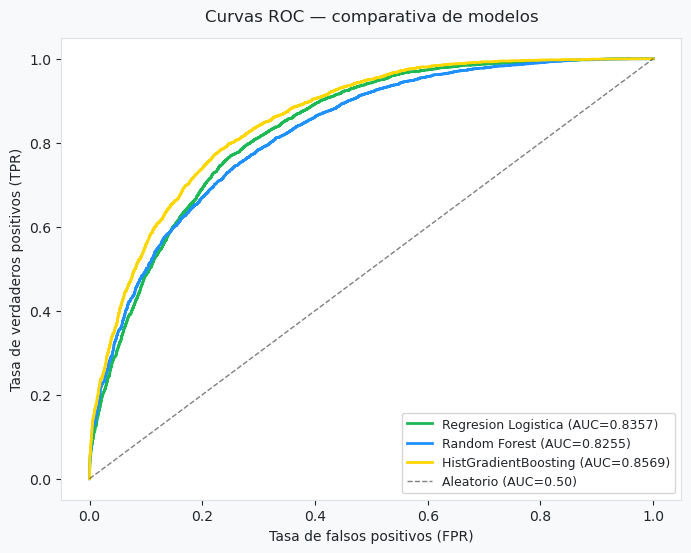

[graficos] Guardado: output\graficos\08_curvas_roc.png


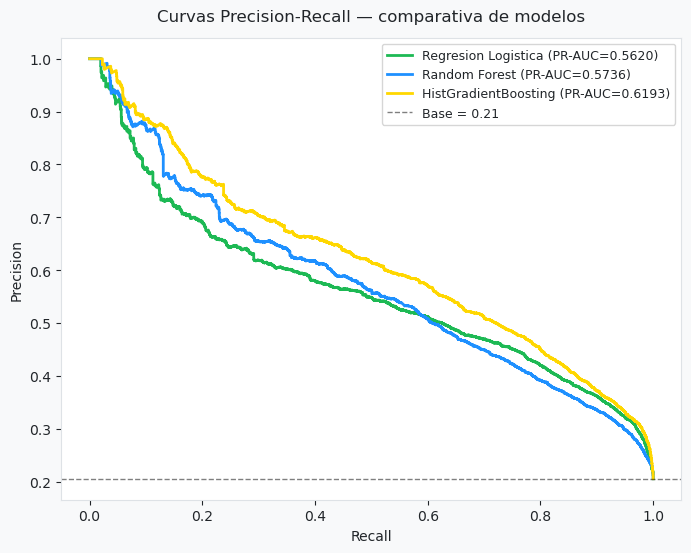

[graficos] Guardado: output\graficos\09_curvas_pr.png


In [5]:
gr.grafico_roc(res, y_test)
gr.grafico_pr(res, y_test)

## 2. Efecto del umbral de decisión
El recall depende del umbral. Con `class_weight="balanced"` el umbral 0.5 favorece el recall y deja pasar muchos falsos positivos. Esta tabla muestra el compromiso para el mejor modelo.

In [6]:
cv = pd.read_csv(os.path.join("output", "modelos", "resultados_cv.csv"), index_col=0)
mejor = res_train["mejor"] if "res_train" in globals() else cv["auc_cv"].idxmax()
m = modelos[mejor]
p = res[mejor]["y_proba"]
print(f"Mejor modelo (por AUC de CV): {mejor}")
umbrales = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
pd.DataFrame([{"umbral": u,
               "precision": precision_score(y_test, (p >= u).astype(int), zero_division=0),
               "recall": recall_score(y_test, (p >= u).astype(int)),
               "f1": f1_score(y_test, (p >= u).astype(int)),
               "% de canciones marcadas como hit": (p >= u).mean() * 100} for u in umbrales]).set_index("umbral").round(3)

Mejor modelo (por AUC de CV): HistGradientBoosting


,precision,recall,f1,% de canciones marcadas como hit
umbral,,,,
0.3,0.315,0.967,0.475,63.114
0.4,0.354,0.925,0.512,53.626
0.5,0.425,0.833,0.563,40.202
0.6,0.559,0.613,0.585,22.513
0.7,0.664,0.387,0.489,11.972
0.8,0.787,0.185,0.300,4.824


## 3. ¿Cuánto aporta el género? (ablación)
`train.py` entrena el mejor modelo con y sin las columnas de género y devuelve el AUC de ambos. Son AUC de **validación cruzada agrupada sobre train**, no de test.

In [7]:
abl = res_train.get("ablacion_genero") if "res_train" in globals() else None
ruta_abl = os.path.join("output", "modelos", "ablacion_genero.csv")
if abl is None and os.path.exists(ruta_abl):
    a = pd.read_csv(ruta_abl, index_col=0)["valor"]
    abl = {"auc_con_genero": float(a["auc_con_genero"]), "auc_sin_genero": float(a["auc_sin_genero"])}
if abl:
    print(f"AUC de CV con género: {abl['auc_con_genero']:.4f} | sin género: {abl['auc_sin_genero']:.4f} | aporte del género: {abl['auc_con_genero'] - abl['auc_sin_genero']:+.4f}")
else:
    print("Ejecuta la primera celda de este notebook (o python -m src.train) para obtener la ablación.")

AUC de CV con género: 0.8561 | sin género: 0.6946 | aporte del género: +0.1616


## 4. Recall por género
Revisa si el modelo detecta hits de forma pareja entre géneros o si solo acierta en los géneros con muchos hits.

In [8]:
pred = (p >= 0.5).astype(int)
por_gen = gr.tabla_recall_por_genero(raw_test, y_test, pred)
elegibles = por_gen[por_gen.hits >= 20].dropna(subset=["recall"])
print(f"Géneros con al menos 20 hits en test: {len(elegibles)} de {len(por_gen)}")
print(f"Recall por género: mínimo {elegibles.recall.min():.2f} | mediana {elegibles.recall.median():.2f} | máximo {elegibles.recall.max():.2f}")
pd.concat([elegibles.sort_values("recall").head(8), elegibles.sort_values("recall").tail(8)]).round(2)

Géneros con al menos 20 hits en test: 74 de 114
Recall por género: mínimo 0.09 | mediana 0.87 | máximo 1.00


,n,hits,recall,precision
genero,,,,
j-dance,209.0,23.0,0.09,0.33
jazz,177.0,21.0,0.19,0.27
cantopop,199.0,25.0,0.24,0.23
sertanejo,222.0,33.0,0.33,0.15
pagode,215.0,24.0,0.33,0.30
death-metal,198.0,33.0,0.39,0.37
techno,182.0,41.0,0.44,0.43
trip-hop,192.0,26.0,0.50,0.18
chill,204.0,150.0,1.00,0.74


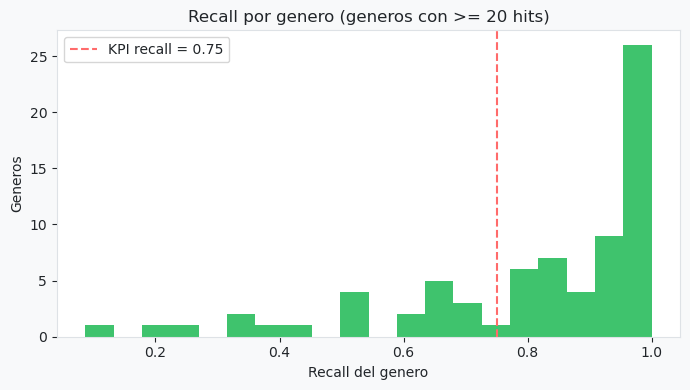

[graficos] Guardado: output\graficos\13_recall_por_genero.png


In [9]:
gr.grafico_recall_por_genero(elegibles)

### 4b. Recall por género sin filtrar
La tabla anterior solo incluye géneros con 20 o más hits, lo que excluye a los de pocos hits (los más difíciles). Aquí se usan **todos** los géneros con al menos un hit y se agrupan por hit rate del género. El recall "global" cuenta cada canción una vez por cada género al que pertenece, por eso difiere levemente del recall del modelo.

In [10]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pred = (p >= 0.5).astype(int)
d = (raw_test[["track_genre"]].assign(y=y_test.values, pred=pred)
     .assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero"))
d["tp"] = ((d.y == 1) & (d.pred == 1)).astype(int)

g = d.groupby("genero").agg(n=("y", "size"), hits=("y", "sum"), marcados=("pred", "sum"), tp=("tp", "sum"))
g["hit_rate_genero"] = g.hits / g.n
g["recall"] = g.tp / g.hits.where(g.hits > 0)
g["precision"] = g.tp / g.marcados.where(g.marcados > 0)

con_hits = g[g.hits > 0]
print(f"Géneros: {len(g)} | con al menos 1 hit en test (recall definido): {len(con_hits)} | sin hits: {(g.hits == 0).sum()}")
print(f"Recall macro (promedio de géneros): {con_hits.recall.mean():.3f} | recall global (por género-canción): {g.tp.sum() / g.hits.sum():.3f}")
print(f"Géneros con recall < 0.75 (KPI): {(con_hits.recall < 0.75).sum()} de {len(con_hits)} ({(con_hits.recall < 0.75).mean()*100:.0f}%)")
rho, _ = spearmanr(con_hits.hit_rate_genero, con_hits.recall)
print(f"Correlación (Spearman) entre hit rate del género y su recall: {rho:.2f}")

tramos = pd.cut(con_hits.hit_rate_genero, [0, 0.10, 0.25, 0.50, 1.0], include_lowest=True,
                labels=["bajo (<10%)", "medio (10-25%)", "alto (25-50%)", "muy alto (>50%)"])
res_tramos = con_hits.groupby(tramos, observed=True).agg(generos=("n", "size"), hits=("hits", "sum"), tp=("tp", "sum"),
                                                  marcados=("marcados", "sum"), n=("n", "sum"), recall_macro=("recall", "mean"))
res_tramos["recall_micro"] = res_tramos.tp / res_tramos.hits
res_tramos["precision_micro"] = res_tramos.tp / res_tramos.marcados
res_tramos["% marcadas como hit"] = res_tramos.marcados / res_tramos.n * 100
res_tramos[["generos", "hits", "recall_micro", "recall_macro", "precision_micro", "% marcadas como hit"]].round(3)

Géneros: 114 | con al menos 1 hit en test (recall definido): 109 | sin hits: 5
Recall macro (promedio de géneros): 0.580 | recall global (por género-canción): 0.846
Géneros con recall < 0.75 (KPI): 56 de 109 (51%)
Correlación (Spearman) entre hit rate del género y su recall: 0.94


,generos,hits,recall_micro,recall_macro,precision_micro,% marcadas como hit
hit_rate_genero,,,,,,
bajo (<10%),35,263,0.148,0.104,0.191,2.925
medio (10-25%),31,1148,0.661,0.625,0.287,42.295
alto (25-50%),33,2567,0.931,0.919,0.430,81.006
muy alto (>50%),10,1241,0.990,0.989,0.673,92.926


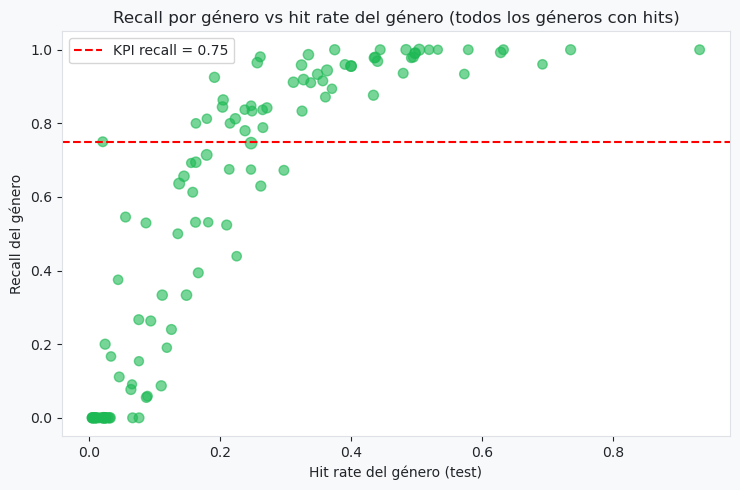

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(con_hits.hit_rate_genero, con_hits.recall, s=con_hits.n / 4, alpha=0.6, color="#1DB954")
ax.axhline(0.75, color="red", ls="--", label="KPI recall = 0.75")
ax.set_xlabel("Hit rate del género (test)"); ax.set_ylabel("Recall del género")
ax.set_title("Recall por género vs hit rate del género (todos los géneros con hits)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join("output", "graficos", "16_recall_vs_hit_rate_genero.png"), dpi=120, bbox_inches="tight"); plt.show()

## 5. Importancia de variables (permutación)
Se permuta cada variable en test y se mide cuánto cae el AUC. Las columnas de género se permutan **juntas, como un solo bloque**: permutarlas una a una no tiene sentido porque cada una es solo un 0/1 de un género.

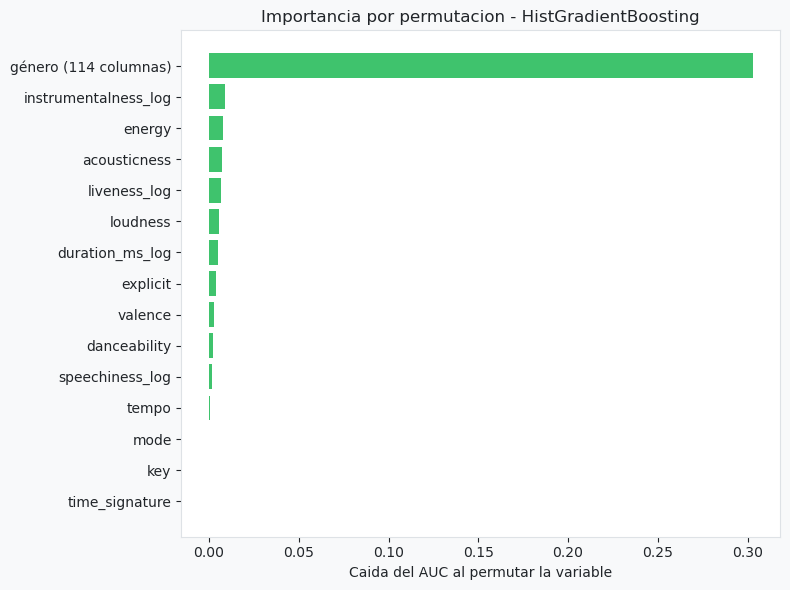

[graficos] Guardado: output\graficos\14_importancia_permutacion.png


,caída AUC
género (114 columnas),0.3029
instrumentalness_log,0.0091
energy,0.0076
acousticness,0.0070
liveness_log,0.0067


In [12]:
imp = gr.tabla_importancia_permutacion(m, X_test, y_test)
gr.grafico_importancia_permutacion(imp, mejor)
imp.sort_values(ascending=False).head(5).round(4).to_frame("caída AUC")

## 6. K-Means (no supervisado)
Se agrupan las canciones solo por sus variables de audio (sin género ni target) y luego se mira si los clusters se asocian con el hit rate.

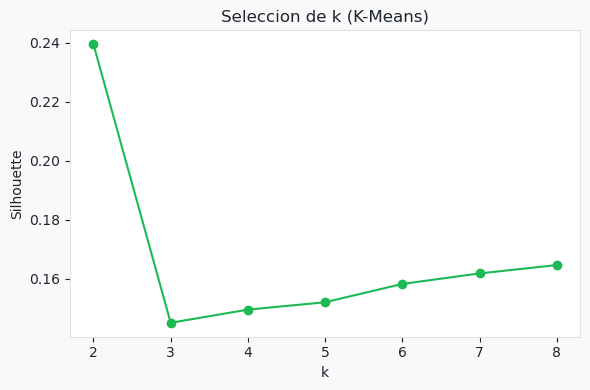

[graficos] Guardado: output\graficos\15_kmeans_silhouette.png
k elegido por silhouette: 2 (silhouette = 0.240)


In [13]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

sc = StandardScaler().fit(X_train[FEATURES_SCALE])
Xk_tr, Xk_te = sc.transform(X_train[FEATURES_SCALE]), sc.transform(X_test[FEATURES_SCALE])

sil = gr.silhouette_kmeans(Xk_tr)
k_opt = gr.grafico_kmeans_silhouette(sil)
print(f"k elegido por silhouette: {k_opt} (silhouette = {sil[k_opt]:.3f})")

In [14]:
km = KMeans(n_clusters=k_opt, n_init=10, random_state=42).fit(Xk_tr)
perfil = (X_test[["danceability", "energy", "acousticness", "valence", "loudness"]]
          .assign(cluster=km.predict(Xk_te), hit=y_test.values))
res_km = perfil.groupby("cluster").agg(n=("hit", "size"), hit_rate=("hit", "mean"),
                                       danceability=("danceability", "mean"), energy=("energy", "mean"),
                                       acousticness=("acousticness", "mean"), valence=("valence", "mean"),
                                       loudness=("loudness", "mean")).round(3)
print(f"Hit rate base en test: {y_test.mean():.3f}")
res_km

Hit rate base en test: 0.205


,n,hit_rate,danceability,energy,acousticness,valence,loudness
cluster,,,,,,,
0,4430,0.191,0.462,0.295,0.755,0.313,-14.664
1,13604,0.210,0.595,0.749,0.189,0.521,-6.446


### 6b. Más criterios para elegir k
Silhouette por sí solo tiende a favorecer k = 2 (la partición más gruesa posible). Se agregan el codo (inercia) y Davies-Bouldin, con el mismo escalado y semilla. El silhouette se calcula sobre una muestra fija de 10.000 canciones porque el cálculo exacto es O(n²).

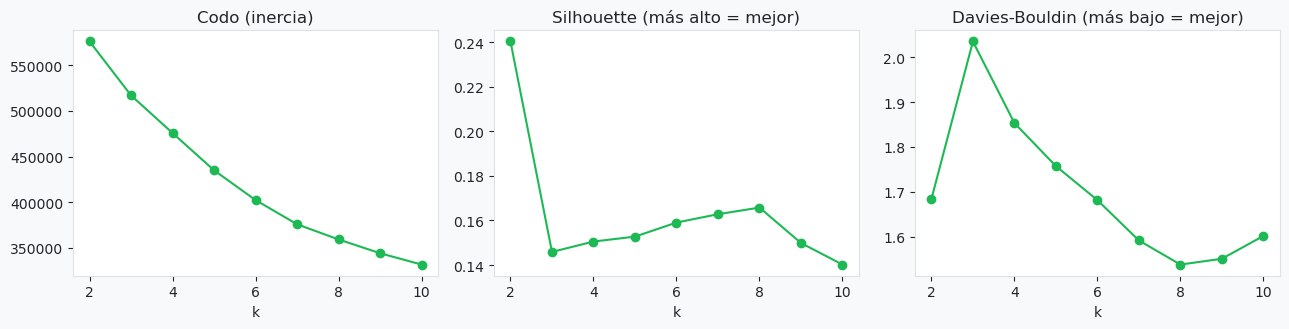

,inercia,silhouette,Davies-Bouldin
k,,,
2,575926.926,0.240,1.684
3,516914.344,0.146,2.035
4,475747.944,0.151,1.853
5,435004.902,0.153,1.757
6,402425.575,0.159,1.681
7,375967.623,0.163,1.591
8,359350.721,0.166,1.537
9,344280.255,0.150,1.550
10,331873.478,0.140,1.601


In [15]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, roc_auc_score
import matplotlib.pyplot as plt

idx_sil = np.random.RandomState(42).choice(len(Xk_tr), 10000, replace=False)   # muestra fija para silhouette
filas_k = []
for k_ in range(2, 11):
    km_k = KMeans(n_clusters=k_, n_init=10, random_state=42).fit(Xk_tr)
    filas_k.append({"k": k_, "inercia": km_k.inertia_,
                    "silhouette": silhouette_score(Xk_tr[idx_sil], km_k.labels_[idx_sil]),
                    "Davies-Bouldin": davies_bouldin_score(Xk_tr, km_k.labels_)})
crit_k = pd.DataFrame(filas_k).set_index("k")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, col, tit in zip(ax, ["inercia", "silhouette", "Davies-Bouldin"],
                       ["Codo (inercia)", "Silhouette (más alto = mejor)", "Davies-Bouldin (más bajo = mejor)"]):
    a.plot(crit_k.index, crit_k[col], marker="o", color="#1DB954"); a.set_title(tit); a.set_xlabel("k")
plt.tight_layout(); plt.savefig(os.path.join("output", "graficos", "17_kmeans_criterios_k.png"), dpi=120, bbox_inches="tight"); plt.show()
crit_k.round(3)

### 6c. Estabilidad de los clusters
Se ajusta el mismo K-Means en dos mitades disjuntas de train y se comparan las etiquetas que cada una asigna a test con el índice de Rand ajustado (ARI: 1 = clusters idénticos, 0 = azar). Un cluster que cambia según la muestra no es un patrón.

In [16]:
perm = np.random.RandomState(42).permutation(len(Xk_tr))
mitad_a, mitad_b = perm[: len(perm) // 2], perm[len(perm) // 2:]
filas_est = []
for k_ in range(2, 9):
    la = KMeans(n_clusters=k_, n_init=10, random_state=42).fit(Xk_tr[mitad_a]).predict(Xk_te)
    lb = KMeans(n_clusters=k_, n_init=10, random_state=42).fit(Xk_tr[mitad_b]).predict(Xk_te)
    filas_est.append({"k": k_, "ARI entre mitades": adjusted_rand_score(la, lb)})
est_k = pd.DataFrame(filas_est).set_index("k")
est_k.round(3).T

k,2,3,4,5,6,7,8
ARI entre mitades,0.984,0.962,0.957,0.974,0.978,0.973,0.677


### 6d. Segmentación con k ≥ 3: perfil, géneros y valor predictivo
Con k = 2 solo se separa "tranquilo/acústico" de "enérgico". Para segmentar un catálogo se exige k ≥ 3 y estabilidad (ARI ≥ 0,90 en 6c), y entre los k que cumplen se toma el de mayor silhouette. Se perfilan los clusters con todas las variables de audio (en test y en train), se revisa qué géneros los componen y se mide cuánta señal de hit contienen: el AUC de usar solo el hit rate del cluster.

In [17]:
from IPython.display import display
from sklearn.decomposition import PCA

genre_cols = [c for c in X_train.columns if c.startswith("genre_")]
y_train = pd.read_csv("data/processed/train/y_train.csv").squeeze()
k_ok = [k_ for k_ in est_k.index if k_ >= 3 and est_k.loc[k_, "ARI entre mitades"] >= 0.90]    # k >= 3 y estable
k_seg = int(crit_k.loc[k_ok, "silhouette"].idxmax())
km_seg = KMeans(n_clusters=k_seg, n_init=10, random_state=42).fit(Xk_tr)
lab_tr, lab_te = km_seg.labels_, km_seg.predict(Xk_te)
print(f"k de segmentación: {k_seg} (silhouette {crit_k.loc[k_seg, 'silhouette']:.3f}) | hit rate base en test: {y_test.mean():.3f}")

def perfil_clusters(X, y, lab):
    d = X[FEATURES_SCALE + ["explicit"]].assign(cluster=lab, hit=np.asarray(y))
    out = d.groupby("cluster").agg(n=("hit", "size"), hit_rate=("hit", "mean"), explicit=("explicit", "mean"),
                                   **{c: (c, "mean") for c in FEATURES_SCALE})
    out.insert(1, "% canciones", out["n"] / out["n"].sum() * 100)
    return out.round(3)

print("\nPerfil de los clusters (test):"); display(perfil_clusters(X_test, y_test, lab_te))
print("Perfil de los clusters (train):"); display(perfil_clusters(X_train, y_train, lab_tr))

# Géneros más frecuentes dentro de cada cluster (test)
G_te_f = X_test[genre_cols].values.astype(float)
comp = pd.DataFrame(G_te_f, columns=[c.replace("genre_", "") for c in genre_cols]).groupby(lab_te).mean()
top_gen = {f"cluster {c}": ", ".join(f"{g} ({comp.loc[c, g] * 100:.0f}%)" for g in comp.loc[c].nlargest(5).index) for c in comp.index}
display(pd.Series(top_gen, name="5 géneros más frecuentes (% de las canciones del cluster)").to_frame())

# ¿Cuánta señal de hit hay en el cluster de audio?
tasa_cl = pd.Series(np.asarray(y_train)).groupby(lab_tr).mean()
auc_cl = roc_auc_score(y_test, tasa_cl.reindex(lab_te).values)
print(f"AUC en test usando solo el hit rate del cluster de audio (tasas de train): {auc_cl:.3f}  (azar = 0.5; solo género ≈ 0.83; modelo completo ≈ 0.86)")

k de segmentación: 7 (silhouette 0.163) | hit rate base en test: 0.205

Perfil de los clusters (test):


,n,% canciones,hit_rate,explicit,danceability,energy,loudness,valence,tempo,acousticness,speechiness_log,instrumentalness_log,liveness_log,duration_ms_log
cluster,,,,,,,,,,,,,,
0,5102,28.291,0.236,0.110,0.703,0.723,-6.427,0.714,119.414,0.224,0.072,0.018,0.149,12.199
1,870,4.824,0.166,0.437,0.659,0.668,-8.155,0.517,118.664,0.405,0.376,0.025,0.258,12.081
2,1368,7.586,0.176,0.002,0.347,0.174,-21.282,0.184,103.457,0.858,0.049,0.555,0.149,12.116
3,3414,18.931,0.231,0.033,0.531,0.370,-10.647,0.398,113.579,0.694,0.048,0.029,0.144,12.201
4,3893,21.587,0.244,0.086,0.467,0.816,-5.322,0.365,139.485,0.073,0.073,0.028,0.172,12.342
5,2003,11.107,0.101,0.040,0.581,0.749,-8.459,0.336,127.014,0.100,0.066,0.568,0.151,12.488
6,1384,7.674,0.125,0.061,0.510,0.759,-6.971,0.491,123.353,0.276,0.076,0.059,0.531,12.311


Perfil de los clusters (train):


,n,% canciones,hit_rate,explicit,danceability,energy,loudness,valence,tempo,acousticness,speechiness_log,instrumentalness_log,liveness_log,duration_ms_log
cluster,,,,,,,,,,,,,,
0,20106,28.039,0.244,0.105,0.702,0.721,-6.480,0.710,118.463,0.217,0.070,0.018,0.144,12.206
1,3412,4.758,0.171,0.407,0.657,0.653,-8.457,0.517,116.565,0.412,0.381,0.022,0.262,12.089
2,5343,7.451,0.169,0.003,0.342,0.172,-21.179,0.182,102.006,0.858,0.049,0.562,0.145,12.110
3,13991,19.512,0.226,0.035,0.527,0.372,-10.652,0.393,113.039,0.694,0.046,0.033,0.144,12.223
4,15328,21.376,0.250,0.101,0.471,0.809,-5.412,0.366,139.130,0.079,0.074,0.029,0.169,12.339
5,8154,11.371,0.111,0.036,0.583,0.750,-8.398,0.340,127.616,0.095,0.066,0.569,0.150,12.487
6,5372,7.492,0.143,0.058,0.521,0.757,-6.939,0.513,123.664,0.281,0.075,0.058,0.535,12.300


,5 géneros más frecuentes (% de las canciones del cluster)
cluster 0,"hip-hop (3%), reggaeton (3%), latino (3%), lat..."
cluster 1,"comedy (19%), j-dance (10%), dancehall (7%), f..."
cluster 2,"new-age (12%), sleep (12%), ambient (10%), cla..."
cluster 3,"singer-songwriter (4%), songwriter (4%), tango..."
cluster 4,"metalcore (5%), metal (4%), dubstep (4%), heav..."
cluster 5,"minimal-techno (9%), detroit-techno (8%), tech..."
cluster 6,"pagode (8%), sertanejo (7%), samba (6%), mpb (..."


AUC en test usando solo el hit rate del cluster de audio (tasas de train): 0.576  (azar = 0.5; solo género ≈ 0.83; modelo completo ≈ 0.86)


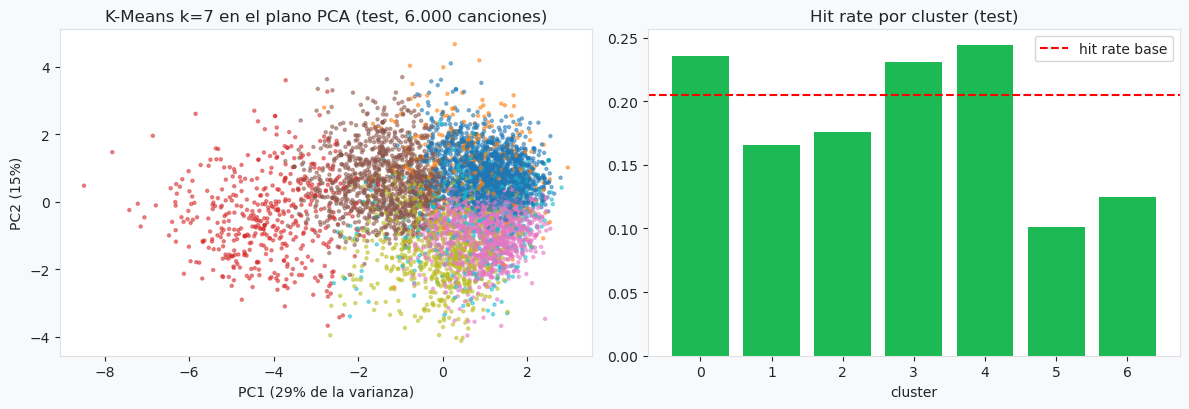

In [18]:
pca = PCA(n_components=2, random_state=42).fit(Xk_tr)
Z = pca.transform(Xk_te)
muestra = np.random.RandomState(42).choice(len(Z), 6000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(Z[muestra, 0], Z[muestra, 1], c=lab_te[muestra], cmap="tab10", s=5, alpha=0.5)
ax[0].set_title(f"K-Means k={k_seg} en el plano PCA (test, 6.000 canciones)")
ax[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.0f}% de la varianza)")
ax[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.0f}%)")
hr = pd.Series(np.asarray(y_test)).groupby(lab_te).mean()
ax[1].bar(hr.index.astype(str), hr.values, color="#1DB954")
ax[1].axhline(np.mean(y_test), color="red", ls="--", label="hit rate base")
ax[1].set_title("Hit rate por cluster (test)"); ax[1].set_xlabel("cluster"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join("output", "graficos", "18_kmeans_pca_clusters.png"), dpi=120, bbox_inches="tight"); plt.show()

### 6e. Segmentación de géneros por su perfil de audio (dos técnicas)
El hit lo explica sobre todo el género, así que la pregunta de negocio más útil es otra: **¿qué tipos de género existen según cómo suenan y cómo se comporta su popularidad?** Cada género (114) se describe por el audio medio de sus canciones en train (estandarizado). Se agrupan con K-Means y con clustering jerárquico (Ward) y se mide su acuerdo con el ARI. El hit rate **no** entra al clustering; se usa después para interpretar los grupos. Luego se cruza con el recall del modelo en test.

In [19]:
from sklearn.cluster import AgglomerativeClustering
from scipy.stats import spearmanr

nombres_gen = [c.replace("genre_", "") for c in genre_cols]
G_tr_f = X_train[genre_cols].values.astype(float)
n_gen_tr = np.maximum(G_tr_f.sum(axis=0), 1)
perfil_gen = pd.DataFrame((G_tr_f.T @ Xk_tr) / n_gen_tr[:, None], index=nombres_gen, columns=FEATURES_SCALE)   # audio medio por género
hit_gen_tr = pd.Series((G_tr_f.T @ np.asarray(y_train, dtype=float)) / n_gen_tr, index=nombres_gen)

sil_gen = {k_: silhouette_score(perfil_gen, KMeans(n_clusters=k_, n_init=20, random_state=42).fit_predict(perfil_gen)) for k_ in range(2, 9)}
k_gen = max((k_ for k_ in sil_gen if k_ >= 3), key=sil_gen.get)           # k >= 3, mayor silhouette
print("Silhouette por k (géneros):", {k_: round(v, 3) for k_, v in sil_gen.items()})
km_gen = KMeans(n_clusters=k_gen, n_init=20, random_state=42).fit(perfil_gen)
lab_gen = km_gen.labels_
lab_ward = AgglomerativeClustering(n_clusters=k_gen, linkage="ward").fit_predict(perfil_gen)
print(f"k elegido = {k_gen} | acuerdo K-Means vs jerárquico (ARI) = {adjusted_rand_score(lab_gen, lab_ward):.3f}")

# Cruce con el hit rate (train y test) y con el recall del modelo oficial (umbral 0.5, test)
y_te_f = np.asarray(y_test, dtype=float)
hits_g = G_te_f.T @ y_te_f
tp_g = G_te_f.T @ (y_te_f * (p >= 0.5))
tabla_g = pd.DataFrame({"cluster": lab_gen, "hit_rate_train": hit_gen_tr.values,
                        "hit_rate_test": hits_g / np.maximum(G_te_f.sum(axis=0), 1),
                        "hits_test": hits_g, "tp_test": tp_g}, index=nombres_gen)
resumen_gen = tabla_g.groupby("cluster").agg(generos=("hit_rate_train", "size"), hit_rate_medio=("hit_rate_train", "mean"),
                                             hit_rate_min=("hit_rate_train", "min"), hit_rate_max=("hit_rate_train", "max"),
                                             hits_test=("hits_test", "sum"), tp_test=("tp_test", "sum"))
resumen_gen["recall (umbral 0.5)"] = resumen_gen.tp_test / resumen_gen.hits_test
resumen_gen = resumen_gen.drop(columns=["hits_test", "tp_test"]).join(
    perfil_gen.groupby(lab_gen)[["acousticness", "energy", "danceability", "instrumentalness_log", "speechiness_log"]].mean())
cerca = pd.DataFrame(km_gen.transform(perfil_gen), index=nombres_gen)
resumen_gen["géneros más típicos"] = [", ".join(cerca[tabla_g.cluster.values == c][c].nsmallest(4).index) for c in resumen_gen.index]
display(resumen_gen.round(3))

corr_gen = pd.Series({c: spearmanr(perfil_gen[c], hit_gen_tr)[0] for c in FEATURES_SCALE}).sort_values()
print("Spearman entre el audio medio del género y su hit rate (114 géneros):")
display(corr_gen.round(2).to_frame("rho").T)

Silhouette por k (géneros): {2: 0.347, 3: 0.241, 4: 0.239, 5: 0.214, 6: 0.24, 7: 0.226, 8: 0.22}
k elegido = 3 | acuerdo K-Means vs jerárquico (ARI) = 0.471


,generos,hit_rate_medio,hit_rate_min,hit_rate_max,recall (umbral 0.5),acousticness,energy,danceability,instrumentalness_log,speechiness_log,géneros más típicos
cluster,,,,,,,,,,,
0,59,0.245,0.0,0.653,0.852,-0.583,0.521,0.145,-0.046,0.018,"groove, dub, alternative, alt-rock"
1,12,0.119,0.0,0.465,0.718,1.088,-1.149,-0.833,1.098,-0.236,"piano, ambient, guitar, disney"
2,43,0.246,0.0,0.945,0.857,0.384,-0.325,0.105,-0.386,-0.021,"soul, indie, indie-pop, indian"


Spearman entre el audio medio del género y su hit rate (114 géneros):


,liveness_log,instrumentalness_log,speechiness_log,duration_ms_log,acousticness,valence,energy,tempo,danceability,loudness
rho,-0.3,-0.13,-0.1,-0.1,-0.07,-0.07,-0.02,-0.01,0.1,0.15


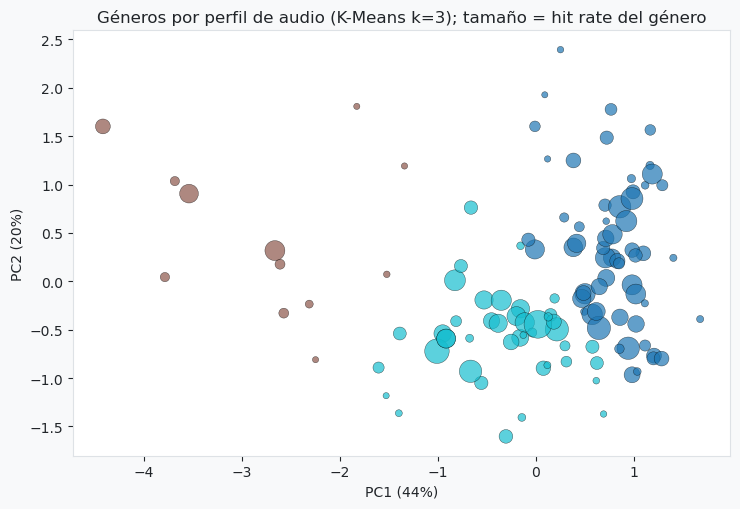

In [20]:
pg = PCA(n_components=2, random_state=42).fit(perfil_gen)
Zg = pg.transform(perfil_gen)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sc_g = ax.scatter(Zg[:, 0], Zg[:, 1], c=lab_gen, cmap="tab10", s=20 + 400 * hit_gen_tr.values, alpha=0.7, edgecolor="k", linewidth=0.3)
ax.set_title(f"Géneros por perfil de audio (K-Means k={k_gen}); tamaño = hit rate del género")
ax.set_xlabel(f"PC1 ({pg.explained_variance_ratio_[0] * 100:.0f}%)"); ax.set_ylabel(f"PC2 ({pg.explained_variance_ratio_[1] * 100:.0f}%)")
plt.tight_layout(); plt.savefig(os.path.join("output", "graficos", "19_kmeans_generos.png"), dpi=120, bbox_inches="tight"); plt.show()

### Lectura del K-Means ampliado
- **Elección de k.** El silhouette más alto es k = 2 (0,240), pero solo separa tranquilo de enérgico. Desde k = 3 los valores son bajos y parecidos (0,14 a 0,17): el audio no tiene una estructura de grupos nítida. La estabilidad es alta hasta k = 7 (ARI ≥ 0,957) y cae en k = 8 (0,677), por eso se segmenta con **k = 7**, y los perfiles de train y test casi coinciden.
- **Los clusters son familias de estilo, no niveles de popularidad.** Se reconocen grupos como ambient/sleep/clásica, techno instrumental, metal y dubstep, música brasileña en vivo, comedia y habla explícita, pop urbano bailable y cantautor acústico.
- **La señal de hit es débil.** Los hit rate van de ≈ 0,10 a ≈ 0,24 (base 0,205). Los grupos claramente bajos son el techno instrumental (≈ 0,10) y la música en vivo (≈ 0,13); el resto está entre 0,17 y 0,24. Usar solo el cluster de audio da un AUC de **0,576**, frente a ≈ 0,83 del género y ≈ 0,86 del modelo.
- **Segmentos de géneros (k = 3).** El silhouette favorece k = 2 (0,347), pero se exige k ≥ 3 (0,241). El acuerdo entre K-Means y Ward es moderado (ARI 0,47), así que estos grupos no son muy robustos. Un grupo pequeño de 12 géneros (piano, ambient, guitar, disney: acústicos, instrumentales y de baja energía) tiene hit rate medio 0,12 frente a 0,245 de los otros dos, y el modelo lo detecta peor (recall 0,72 frente a 0,85). Dentro de cada grupo hay géneros con hit rate 0 y, en los dos grupos grandes, otros de 0,65 a 0,95: el perfil de audio de un género no determina su popularidad. La variable de audio más asociada al hit rate del género es `liveness` (Spearman −0,30).
- **Uso de negocio:** el no supervisado sirve para segmentar el catálogo por estilo y adaptar campañas; no sustituye la información de género ni predice popularidad por sí solo.

## 7. Sensibilidad: split agrupado por artista
El split del pipeline agrupa por canción, y casi todo el test contiene artistas ya vistos en train. Aquí se re-divide train+test agrupando por **artista principal** (primer artista de la cadena), recalculando el P80 solo con el nuevo train, y se compara con la agrupación actual usando 3 semillas y los hiperparámetros del mejor modelo. Una colaboración puede seguir conectando artistas, por eso se reporta el % de test con artista visto.

In [21]:
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, precision_score, recall_score, average_precision_score

# Pool = train + test originales (mismo orden que X_train / X_test); se re-divide con distintos criterios de agrupación
raw_train = pd.read_csv("data/raw/train/raw_train.csv")
pool_raw = pd.concat([raw_train, raw_test], ignore_index=True)
X_pool = pd.concat([X_train, X_test], ignore_index=True)
assert len(pool_raw) == len(X_pool)

pool_raw["artista_principal"] = pool_raw["artists"].str.split(";").str[0].str.strip().str.lower()

def solape_artistas(raw_tr, raw_te):
    """% de canciones de test con al menos un artista individual presente en train."""
    en_train = set(raw_tr["artists"].str.lower().str.split(";").explode().str.strip())
    return raw_te["artists"].str.lower().str.split(";").apply(lambda l: any(a.strip() in en_train for a in l)).mean()

def evaluar_split(grupos, semilla):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=semilla)
    i_tr, i_te = next(gss.split(X_pool, groups=grupos))
    umbral_tr = pool_raw["popularity"].iloc[i_tr].quantile(0.80)             # P80 solo con el nuevo train
    y_all = (pool_raw["popularity"] >= umbral_tr).astype(int)
    mod = clone(modelos[mejor]).fit(X_pool.iloc[i_tr], y_all.iloc[i_tr])      # mismos hiperparámetros del mejor modelo
    p_s = mod.predict_proba(X_pool.iloc[i_te])[:, 1]
    yt, pred_s = y_all.iloc[i_te], (p_s >= 0.5).astype(int)
    k = int(len(yt) * 0.10)
    return {"AUC": roc_auc_score(yt, p_s), "PR-AUC": average_precision_score(yt, p_s),
            "Recall": recall_score(yt, pred_s), "Precision": precision_score(yt, pred_s),
            "Lift@10%": yt.values[np.argsort(-p_s)[:k]].mean() / yt.mean(),
            "% test con artista visto": solape_artistas(pool_raw.iloc[i_tr], pool_raw.iloc[i_te]) * 100}

filas = []
for semilla in (42, 43, 44):
    for nombre, grupos in (("Por canción (actual)", pool_raw["song_key"]),
                           ("Por artista principal", pool_raw["artista_principal"])):
        filas.append({"Agrupación": nombre, "semilla": semilla, **evaluar_split(grupos, semilla)})
sens = pd.DataFrame(filas)
print(f"Modelo evaluado: {mejor} | 3 semillas por criterio")
sens.drop(columns="semilla").groupby("Agrupación").agg(["mean", "std"]).round(4)

Modelo evaluado: HistGradientBoosting | 3 semillas por criterio


AUC          PR-AUC          Recall          \
                         mean     std    mean     std    mean     std   
Agrupación                                                              
Por artista principal  0.8451  0.0043  0.6047  0.0109  0.8119  0.0181   
Por canción (actual)   0.8562  0.0029  0.6222  0.0088  0.8319  0.0071   

                      Precision         Lift@10%          \
                           mean     std     mean     std   
Agrupación                                                 
Por artista principal    0.4251  0.0066   3.2267  0.0204   
Por canción (actual)     0.4218  0.0031   3.3634  0.0177   

                      % test con artista visto          
                                          mean     std  
Agrupación                                              
Por artista principal                  36.2673  2.0626  
Por canción (actual)                   91.6397  0.0753

## 8. Sensibilidad: excluir popularidad 0
La popularidad 0 se concentra en ciertos géneros y artistas y hoy cuenta como "no hit". Aquí se excluye de train **y** test, se recalcula el P80 solo con train y se compara con el escenario actual, con y sin las columnas de género (ablación: se anulan las columnas `genre_*`). Los dos escenarios usan conjuntos de test distintos y definiciones de hit distintas, por lo que los AUC no son estrictamente comparables; lo que importa es si el aporte del género cambia.

In [22]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, precision_score, recall_score, average_precision_score

genre_cols = [c for c in X_train.columns if c.startswith("genre_")]
y_train = pd.read_csv("data/processed/train/y_train.csv").squeeze()
raw_train = pd.read_csv("data/raw/train/raw_train.csv")

def sin_genero(X):
    """Ablación: se anulan las columnas de género (el modelo solo puede usar audio y metadatos)."""
    X = X.copy(); X[genre_cols] = 0
    return X

def ajustar_evaluar(Xtr, ytr, Xte, yte):
    mod = clone(modelos[mejor]).fit(Xtr, ytr)                 # mismos hiperparámetros del mejor modelo
    p_ = mod.predict_proba(Xte)[:, 1]
    pred_ = (p_ >= 0.5).astype(int)
    k = int(len(yte) * 0.10)
    return {"n test": len(yte), "hit rate test": float(np.mean(yte)),
            "AUC": roc_auc_score(yte, p_), "PR-AUC": average_precision_score(yte, p_),
            "Recall": recall_score(yte, pred_), "Precision": precision_score(yte, pred_),
            "Lift@10%": np.asarray(yte)[np.argsort(-p_)[:k]].mean() / np.mean(yte)}

# Escenario sin popularidad 0: se excluye de train Y de test y el P80 se recalcula solo con train
mask_tr = (raw_train["popularity"] > 0).values
mask_te = (raw_test["popularity"] > 0).values
print(f"Canciones con popularidad 0 excluidas -> train: {(~mask_tr).mean()*100:.1f}% | test: {(~mask_te).mean()*100:.1f}%")
umbral0 = raw_train.loc[mask_tr, "popularity"].quantile(0.80)
print(f"P80 sin popularidad 0 (train): {umbral0} (con popularidad 0: 52.0)")
y_tr0 = (raw_train.loc[mask_tr, "popularity"] >= umbral0).astype(int).values
y_te0 = (raw_test.loc[mask_te, "popularity"] >= umbral0).astype(int).values
Xtr0, Xte0 = X_train[mask_tr], X_test[mask_te]

filas = {
    "Actual (pop 0 = no hit) | con género":  ajustar_evaluar(X_train, y_train, X_test, y_test),
    "Actual (pop 0 = no hit) | solo audio":  ajustar_evaluar(sin_genero(X_train), y_train, sin_genero(X_test), y_test),
    "Sin popularidad 0       | con género":  ajustar_evaluar(Xtr0, y_tr0, Xte0, y_te0),
    "Sin popularidad 0       | solo audio":  ajustar_evaluar(sin_genero(Xtr0), y_tr0, sin_genero(Xte0), y_te0),
}
tabla_pop0 = pd.DataFrame(filas).T.round(4)
print(f"Aporte del género (AUC con género - solo audio): actual {tabla_pop0.iloc[0].AUC - tabla_pop0.iloc[1].AUC:+.3f} | "
      f"sin popularidad 0 {tabla_pop0.iloc[2].AUC - tabla_pop0.iloc[3].AUC:+.3f}")
tabla_pop0

Canciones con popularidad 0 excluidas -> train: 10.3% | test: 11.0%
P80 sin popularidad 0 (train): 54.0 (con popularidad 0: 52.0)
Aporte del género (AUC con género - solo audio): actual +0.164 | sin popularidad 0 +0.169


,n test,hit rate test,AUC,PR-AUC,Recall,Precision,Lift@10%
Actual (pop 0 = no hit) | con género,18034.0,0.2053,0.8569,0.6193,0.8331,0.4254,3.3557
Actual (pop 0 = no hit) | solo audio,18034.0,0.2053,0.6932,0.3478,0.6869,0.3037,1.9642
Sin popularidad 0 | con género,16051.0,0.2024,0.8800,0.6672,0.8464,0.4527,3.6271
Sin popularidad 0 | solo audio,16051.0,0.2024,0.7107,0.3695,0.7054,0.3012,2.1861


## 9. Sensibilidad: target relativo al género
Si el género casi determina el hit, queda la duda de si el audio predice algo **dentro** de cada género. Aquí el hit se redefine como popularidad ≥ P80 **del género** (umbrales calculados solo con train; una canción con varios géneros usa el promedio de los umbrales de sus géneros). Con esta definición el hit rate es ≈ 20% en todos los géneros, así que el género deja de ser un predictor "gratis". Es un problema de negocio distinto ("¿será hit dentro de su género?") y se usa solo como prueba de sensibilidad. En géneros con muchos ceros el umbral es muy bajo, lo que vuelve ruidosa la etiqueta ahí.

In [23]:
from scipy.stats import spearmanr

gtr = raw_train[["track_genre", "popularity"]].assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero")
umbral_genero = gtr.groupby("genero")["popularity"].quantile(0.80)
umbral_global = raw_train["popularity"].quantile(0.80)

def umbral_cancion(raw):
    e = raw[["track_genre"]].assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero")
    e["u"] = e["genero"].map(umbral_genero).fillna(umbral_global)          # género no visto -> umbral global
    return e.groupby(level=0)["u"].mean().reindex(raw.index).values

y_tr_rel = (raw_train["popularity"].values >= umbral_cancion(raw_train)).astype(int)
y_te_rel = (raw_test["popularity"].values >= umbral_cancion(raw_test)).astype(int)
print(f"Hit rate con target relativo -> train: {y_tr_rel.mean():.3f} | test: {y_te_rel.mean():.3f}")
print(f"Umbral P80 por género: mínimo {umbral_genero.min():.0f}, mediana {umbral_genero.median():.0f}, máximo {umbral_genero.max():.0f}")

res_rel = {
    "Target relativo | con género": ajustar_evaluar(X_train, y_tr_rel, X_test, y_te_rel),
    "Target relativo | solo audio": ajustar_evaluar(sin_genero(X_train), y_tr_rel, sin_genero(X_test), y_te_rel),
}
tabla_rel = pd.DataFrame(res_rel).T.round(4)
print(f"Aporte del género con target relativo (AUC con género - solo audio): {tabla_rel.iloc[0].AUC - tabla_rel.iloc[1].AUC:+.3f}")
tabla_rel

Hit rate con target relativo -> train: 0.198 | test: 0.198
Umbral P80 por género: mínimo 3, mediana 51, máximo 75
Aporte del género con target relativo (AUC con género - solo audio): +0.078


,n test,hit rate test,AUC,PR-AUC,Recall,Precision,Lift@10%
Target relativo | con género,18034.0,0.1981,0.6565,0.3304,0.6128,0.2735,1.8929
Target relativo | solo audio,18034.0,0.1981,0.5782,0.2552,0.5454,0.2335,1.4365


In [24]:
# ¿Se parejó el recall entre géneros? (modelo con género, target relativo, umbral 0.5)
mod_rel = clone(modelos[mejor]).fit(X_train, y_tr_rel)
pred_rel = (mod_rel.predict_proba(X_test)[:, 1] >= 0.5).astype(int)

def recall_por_genero(raw, y, pred):
    d = (raw[["track_genre"]].assign(y=np.asarray(y), pred=pred)
         .assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero"))
    d["tp"] = ((d.y == 1) & (d.pred == 1)).astype(int)
    g = d.groupby("genero").agg(hits=("y", "sum"), tp=("tp", "sum"), n=("y", "size"), marcados=("pred", "sum"))
    g = g[g.hits > 0]
    g["recall"] = g.tp / g.hits
    g["hit_rate_genero"] = g.hits / g.n
    return g

g_abs = recall_por_genero(raw_test, y_test, (p >= 0.5).astype(int))   # target absoluto (modelo original)
g_rel = recall_por_genero(raw_test, y_te_rel, pred_rel)               # target relativo al género
comp = pd.DataFrame({
    "géneros con hits": [len(g_abs), len(g_rel)],
    "recall macro": [g_abs.recall.mean(), g_rel.recall.mean()],
    "desv. estándar del recall entre géneros": [g_abs.recall.std(), g_rel.recall.std()],
    "% géneros con recall < 0.75": [(g_abs.recall < 0.75).mean() * 100, (g_rel.recall < 0.75).mean() * 100],
    "Spearman (hit rate del género, recall)": [spearmanr(g_abs.hit_rate_genero, g_abs.recall)[0],
                                               spearmanr(g_rel.hit_rate_genero, g_rel.recall)[0]],
}, index=["Target absoluto (actual)", "Target relativo al género"]).round(3)
comp

,géneros con hits,recall macro,desv. estándar del recall entre géneros,% géneros con recall < 0.75,"Spearman (hit rate del género, recall)"
Target absoluto (actual),109,0.580,0.389,51.376,0.938
Target relativo al género,114,0.615,0.175,77.193,0.242


## 10. Umbral de decisión calibrado sin mirar test
La sección 2 muestra el efecto del umbral directamente sobre test; eso sirve para describir, **no** para elegir. Aquí los umbrales se calibran con probabilidades **fuera de muestra de train** (CV agrupada de 5 folds) y test se usa una sola vez para reportar. Estas secciones **no modifican el modelo oficial**: solo comparan alternativas.

In [25]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

y_train = pd.read_csv("data/processed/train/y_train.csv").squeeze()
g_train = pd.read_csv("data/processed/train/g_train.csv").squeeze()
genre_cols = [c for c in X_train.columns if c.startswith("genre_")]

# Probabilidades FUERA DE MUESTRA en train (se reutilizan si ya existen)
if "oof" not in globals():
    cv_oof = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    oof = np.zeros(len(X_train))
    for i_tr, i_va in cv_oof.split(X_train, y_train, g_train):
        oof[i_va] = clone(modelos[mejor]).fit(X_train.iloc[i_tr], y_train.iloc[i_tr]).predict_proba(X_train.iloc[i_va])[:, 1]
print(f"AUC fuera de muestra en train: {roc_auc_score(y_train, oof):.4f}")

def metricas_umbral(y, prob, u):
    pred = (prob >= u).astype(int)
    return {"umbral": round(float(u), 3), "Precisión": precision_score(y, pred), "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred), "% marcadas": pred.mean() * 100}

malla_u = np.round(np.arange(0.20, 0.86, 0.01), 2)
f1_oof = np.array([f1_score(y_train, (oof >= u).astype(int)) for u in malla_u])
u_f1 = malla_u[f1_oof.argmax()]                                    # máximo F1 en train (fuera de muestra)
u_rec = np.quantile(oof[np.asarray(y_train) == 1], 1 - 0.78)       # recall 0.78 en train (margen sobre el KPI de 0.75)
f1_te = np.array([f1_score(y_test, (p >= u).astype(int)) for u in malla_u])
print(f"Umbral que maximiza F1 en train (OOF): {u_f1:.2f} | mejor umbral mirando test (solo referencia): {malla_u[f1_te.argmax()]:.2f}")
pd.DataFrame({"0.5 (actual)": metricas_umbral(y_test, p, 0.5),
              "Máx. F1 (calibrado en train)": metricas_umbral(y_test, p, u_f1),
              "Recall 0.78 (calibrado en train)": metricas_umbral(y_test, p, u_rec)}).T.round(3)

AUC fuera de muestra en train: 0.8561
Umbral que maximiza F1 en train (OOF): 0.56 | mejor umbral mirando test (solo referencia): 0.56


,umbral,Precisión,Recall,F1,% marcadas
0.5 (actual),0.500,0.425,0.833,0.563,40.202
Máx. F1 (calibrado en train),0.560,0.518,0.691,0.592,27.376
Recall 0.78 (calibrado en train),0.522,0.456,0.793,0.579,35.705


### 10b. Umbral por género y política suavizada
Un umbral único deja el recall muy desigual entre géneros (sección 4b). Dos alternativas:

- **Umbral por género:** cada género recibe el umbral que logra recall 0,78 sobre sus propios hits (probabilidades fuera de muestra). Un género con menos de 30 hits en train usa el umbral global 0,5. Una canción con varios géneros usa el promedio de los umbrales de sus géneros.
- **Política suavizada:** umbral = λ · (global 0,5) + (1 − λ) · (umbral por género). λ = 1 es el modelo actual y λ = 0 el umbral por género puro.

λ **no se elige mirando test**: los umbrales se calibran con una parte de train (60% de las canciones, agrupadas), la curva de λ se mide en la otra parte (40%) y se toma el menor λ cuyo recall global sigue ≥ 0,78 (margen sobre el KPI de 0,75). Luego los umbrales se recalibran con todo train y test se usa una sola vez.

In [26]:
from IPython.display import display

G_tr_b = X_train[genre_cols].values.astype(bool)
G_te_b = X_test[genre_cols].values.astype(bool)
y_tr_a, y_te_a = np.asarray(y_train).astype(int), np.asarray(y_test).astype(int)
U_GLOBAL, R_OBJ, N_MIN = 0.5, 0.78, 30

def umbrales_genero(prob, y, G, r=R_OBJ, n_min=N_MIN, u_glob=U_GLOBAL):
    """Umbral por género: el que logra recall r sobre sus hits. Con pocos hits, umbral global."""
    u = np.full(G.shape[1], u_glob)
    for j in range(G.shape[1]):
        pos = prob[G[:, j] & (y == 1)]
        if len(pos) >= n_min:
            u[j] = np.quantile(pos, 1 - r)
    return u

def pred_politica(prob, G, u_gen, lam, u_glob=U_GLOBAL):
    u_song = (G.astype(float) @ u_gen) / np.maximum(G.sum(axis=1), 1)    # varios géneros: promedio de umbrales
    return (prob >= lam * u_glob + (1 - lam) * u_song).astype(int)

def metricas_politica(y, pred, G):
    Gf = G.astype(float)
    hits_g, tp_g = Gf.T @ y, Gf.T @ (y * pred)
    ok = hits_g > 0
    rec_g = tp_g[ok] / hits_g[ok]
    tasa_g = (hits_g / np.maximum(Gf.sum(axis=0), 1))[ok]
    bajo = tasa_g < 0.10
    return {"Recall global": recall_score(y, pred), "Precisión": precision_score(y, pred), "F1": f1_score(y, pred),
            "% marcadas": pred.mean() * 100, "Recall macro (géneros)": rec_g.mean(),
            "Recall géneros con hit rate < 10%": tp_g[ok][bajo].sum() / hits_g[ok][bajo].sum(),
            "% géneros con recall >= 0.75": (rec_g >= 0.75).mean() * 100}

# Selección de λ SIN usar test: se calibra en el 60% de train y se mide en el 40% restante (separado por canción)
i_cal, i_val = next(GroupShuffleSplit(n_splits=1, test_size=0.4, random_state=42).split(X_train, groups=g_train))
u_cal = umbrales_genero(oof[i_cal], y_tr_a[i_cal], G_tr_b[i_cal])
lams = np.round(np.arange(0, 1.01, 0.1), 2)
curva_val = pd.DataFrame({lam: metricas_politica(y_tr_a[i_val], pred_politica(oof[i_val], G_tr_b[i_val], u_cal, lam), G_tr_b[i_val])
                          for lam in lams}).T
curva_val.index.name = "λ (1 = umbral global, 0 = por género)"
lam_sel = float(min(l for l in lams if curva_val.loc[l, "Recall global"] >= 0.78))
print(f"λ elegido (menor λ con recall global >= 0.78 en la validación de train): {lam_sel}")
display(curva_val.round(3))

λ elegido (menor λ con recall global >= 0.78 en la validación de train): 0.1


,Recall global,Precisión,F1,% marcadas,Recall macro (géneros),Recall géneros con hit rate < 10%,% géneros con recall >= 0.75
"λ (1 = umbral global, 0 = por género)",,,,,,,
0.0,0.752,0.381,0.506,42.423,0.613,0.390,54.128
0.1,0.783,0.393,0.523,42.800,0.615,0.369,56.881
0.2,0.800,0.402,0.535,42.772,0.614,0.333,54.128
0.3,0.811,0.411,0.545,42.472,0.610,0.300,52.294
0.4,0.816,0.418,0.552,42.007,0.603,0.258,51.376
0.5,0.822,0.422,0.558,41.881,0.597,0.218,50.459
0.6,0.826,0.427,0.563,41.573,0.593,0.202,49.541
0.7,0.829,0.431,0.567,41.385,0.588,0.174,48.624
0.8,0.830,0.434,0.570,41.119,0.582,0.157,46.789


In [27]:
u_fin = umbrales_genero(oof, y_tr_a, G_tr_b)       # recalibrado con todo train (fuera de muestra)
print(f"Géneros con umbral propio: {(u_fin != U_GLOBAL).sum()} de {len(u_fin)} (el resto usa 0.5)")

pred_act  = (p >= U_GLOBAL).astype(int)
pred_sua  = pred_politica(p, G_te_b, u_fin, lam_sel)
pred_gen  = pred_politica(p, G_te_b, u_fin, 0.0)
tabla_pol = pd.DataFrame({"Umbral global 0.5 (actual)": metricas_politica(y_te_a, pred_act, G_te_b),
                          f"Política suavizada (λ = {lam_sel})": metricas_politica(y_te_a, pred_sua, G_te_b),
                          "Umbral por género (λ = 0)": metricas_politica(y_te_a, pred_gen, G_te_b)}).T
tabla_pol.round(3)

Géneros con umbral propio: 90 de 114 (el resto usa 0.5)


,Recall global,Precisión,F1,% marcadas,Recall macro (géneros),Recall géneros con hit rate < 10%,% géneros con recall >= 0.75
Umbral global 0.5 (actual),0.833,0.425,0.563,40.202,0.580,0.148,48.624
Política suavizada (λ = 0.1),0.795,0.373,0.508,43.701,0.641,0.487,54.128
Umbral por género (λ = 0),0.773,0.357,0.488,44.521,0.646,0.536,57.798


### 10c. ¿Las diferencias superan el ruido? (bootstrap)
Los géneros de hit rate bajo tienen pocos hits en test (≈ 7 por género), así que sus recalls son muy variables. Se remuestrean las canciones de test (300 réplicas, mismas réplicas para las tres políticas) y se reportan intervalos del 95%, incluida la **diferencia pareada** frente al modelo actual. Los tramos de hit rate se fijan con la estimación puntual de test.

In [28]:
import scipy.sparse as sp
Gs = sp.csr_matrix(G_te_b.astype(float))
n_te = len(y_te_a)
hits0 = Gs.T @ y_te_a
tasa0 = hits0 / np.maximum(np.asarray(Gs.sum(axis=0)).ravel(), 1)
mask_bajo = (hits0 > 0) & (tasa0 < 0.10)                    # tramo fijo (hit rate del género < 10%)

def stats_boot(w, y, pred):
    hits_g, tp_g = Gs.T @ (w * y), Gs.T @ (w * y * pred)
    ok = hits_g > 0
    return {"Recall global": (w * y * pred).sum() / (w * y).sum(),
            "Precisión": (w * y * pred).sum() / (w * pred).sum(),
            "Recall macro (géneros)": (tp_g[ok] / hits_g[ok]).mean(),
            "Recall géneros con hit rate < 10%": tp_g[mask_bajo].sum() / hits_g[mask_bajo].sum()}

politicas = {"Actual (0.5)": pred_act, f"Suavizada (λ = {lam_sel})": pred_sua, "Por género (λ = 0)": pred_gen}
rng_b = np.random.RandomState(42)
reps = {nombre: [] for nombre in politicas}
for _ in range(300):
    w = np.bincount(rng_b.randint(0, n_te, n_te), minlength=n_te).astype(float)
    for nombre, pr_ in politicas.items():
        reps[nombre].append(stats_boot(w, y_te_a, pr_))
reps = {k_: pd.DataFrame(v) for k_, v in reps.items()}

filas_ci = []
for nombre, df_ in reps.items():
    for met in df_.columns:
        lo, hi = np.percentile(df_[met], [2.5, 97.5])
        filas_ci.append({"política": nombre, "métrica": met, "media": df_[met].mean(), "IC95% inf.": lo, "IC95% sup.": hi})
ci = pd.DataFrame(filas_ci).pivot(index="métrica", columns="política", values=["media", "IC95% inf.", "IC95% sup."]).round(3)
display(ci)

base_nombre = "Actual (0.5)"
dif = []
for nombre in list(politicas)[1:]:
    for met in ["Recall global", "Precisión", "Recall macro (géneros)", "Recall géneros con hit rate < 10%"]:
        d_ = reps[nombre][met] - reps[base_nombre][met]
        dif.append({"política vs actual": nombre, "métrica": met, "diferencia media": d_.mean(),
                    "IC95% inf.": np.percentile(d_, 2.5), "IC95% sup.": np.percentile(d_, 97.5)})
print("Diferencias pareadas frente al modelo actual:")
pd.DataFrame(dif).round(3)

media                     \
política                          Actual (0.5) Por género (λ = 0)   
métrica                                                             
Precisión                                0.425              0.357   
Recall global                            0.832              0.773   
Recall géneros con hit rate < 10%        0.147              0.533   
Recall macro (géneros)                   0.591              0.657   

                                                        IC95% inf.  \
política                          Suavizada (λ = 0.1) Actual (0.5)   
métrica                                                              
Precisión                                       0.373        0.414   
Recall global                                   0.794        0.820   
Recall géneros con hit rate < 10%               0.484        0.107   
Recall macro (géneros)                          0.652        0.572   

                                                                          \
política                          Por género (λ = 0) Suavizada (λ = 0.1)   
métrica                                                                    
Precisión                                      0.347               0.364   
Recall global                                  0.759               0.780   
Recall géneros con hit rate < 10%              0.474               0.425   
Recall macro (géneros)                         0.635               0.629   

                                    IC95% sup.                     \
política                          Actual (0.5) Por género (λ = 0)   
métrica                                                             
Precisión                                0.436              0.367   
Recall global                            0.842              0.785   
Recall géneros con hit rate < 10%        0.191              0.596   
Recall macro (géneros)                   0.615              0.683   

                                                       
política                          Suavizada (λ = 0.1)  
métrica                                                
Precisión                                       0.383  
Recall global                                   0.806  
Recall géneros con hit rate < 10%               0.551  
Recall macro (géneros)                          0.677

Diferencias pareadas frente al modelo actual:


,política vs actual,métrica,diferencia media,IC95% inf.,IC95% sup.
0,Suavizada (λ = 0.1),Recall global,-0.038,-0.051,-0.025
1,Suavizada (λ = 0.1),Precisión,-0.052,-0.058,-0.046
2,Suavizada (λ = 0.1),Recall macro (géneros),0.061,0.046,0.076
3,Suavizada (λ = 0.1),Recall géneros con hit rate < 10%,0.337,0.277,0.399
4,Por género (λ = 0),Recall global,-0.059,-0.074,-0.045
5,Por género (λ = 0),Precisión,-0.069,-0.076,-0.062
6,Por género (λ = 0),Recall macro (géneros),0.067,0.050,0.080
7,Por género (λ = 0),Recall géneros con hit rate < 10%,0.386,0.327,0.447


### Lectura de la sección 10
- **Calibración en train.** El umbral que maximiza F1 en train (0,56) coincide con el mejor mirando test (0,56): la calibración no está sobreajustada. Con 0,56 el F1 sube a 0,592 pero el recall cae a 0,691 y se pierde el KPI. El umbral que da recall 0,78 en train (≈ 0,522) mantiene el KPI (recall 0,793) y mejora la precisión de 0,425 a 0,456.
- **Política suavizada (λ = 0,1, elegido en validación de train, sin usar test).** En test: recall global 0,795 (cumple el KPI), precisión 0,373 (baja desde 0,425), recall macro por género 0,641 (sube desde 0,580) y recall en géneros de hit rate < 10% 0,487 (sube desde 0,148). El Lift@10% no cambia porque el ranking es el mismo; solo cambia dónde se corta. La curva de λ es casi plana entre 0 y 0,2 y en la validación el recall pasa el corte de 0,78 por solo 0,003, así que λ debe leerse como una zona razonable (0,1 a 0,2) y no como un valor exacto.
- **¿Es ruido?** No. Diferencias pareadas con IC 95% frente al modelo actual: recall en géneros pobres +0,34 [0,28; 0,40], recall macro +0,06 [0,05; 0,08], recall global −0,04 [−0,05; −0,03] y precisión −0,05 [−0,06; −0,05].
- **Umbral por género puro (λ = 0):** recall global 0,773 (IC 0,759 a 0,785, sobre el KPI) y precisión 0,357. Con esta calibración (recall 0,78 por género, mínimo 30 hits) cumple el KPI; con menos margen puede quedar bajo 0,75.
- **Límites.** El recall en géneros pobres sigue lejos de 0,75 (0,49). Con ≈ 7 hits por género en test, las cifras por género son ruidosas. Dos canciones idénticas reciben decisiones distintas según su género, lo que es una decisión de política y no solo técnica. Y el modelo sigue apoyándose en el género: esto reparte mejor el error, no lo elimina.

## 11. Búsqueda de hiperparámetros (justificación de la configuración)
Los hiperparámetros oficiales (300 iteraciones, `learning_rate` 0,05, profundidad 6) no salieron de una búsqueda. Aquí se compara la configuración actual con 10 configuraciones aleatorias usando **CV agrupada de 3 folds** sobre train (mismos folds para todas); los candidatos usan hasta 600 iteraciones con parada temprana. Tarda unos minutos. **No cambia el modelo oficial**: es evidencia para justificar (o revisar) la configuración.

In [29]:
from sklearn.model_selection import ParameterSampler, cross_val_score
from sklearn.metrics import average_precision_score

assert "Hist" in mejor, "Esta búsqueda está escrita para HistGradientBoosting"
splits_hp = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42).split(X_train, y_train, g_train))
espacio_hp = {"learning_rate": [0.03, 0.05, 0.08, 0.1], "max_depth": [4, 6, 8, None], "max_leaf_nodes": [15, 31, 63],
              "min_samples_leaf": [20, 50, 100], "l2_regularization": [0, 1, 10]}
cfgs = [{}] + list(ParameterSampler(espacio_hp, n_iter=10, random_state=42))     # {} = configuración actual

def con_params(c):
    m_ = clone(modelos[mejor])
    if c:
        m_.set_params(**{f"clf__{k_}": v for k_, v in c.items()}, clf__max_iter=600, clf__early_stopping=True,
                      clf__n_iter_no_change=20, clf__validation_fraction=0.1)
    return m_

filas_hp = []
for c in cfgs:
    sc_ = cross_val_score(con_params(c), X_train, y_train, cv=splits_hp, scoring="roc_auc", n_jobs=1)
    filas_hp.append({"configuración": c if c else "actual (baseline)", "AUC CV (3 folds)": sc_.mean(), "desv.": sc_.std(), "_cfg": c})
res_hp = pd.DataFrame(filas_hp).sort_values("AUC CV (3 folds)", ascending=False).reset_index(drop=True)
print(f"Mejor configuración: {res_hp.loc[0, 'configuración']}")
res_hp.drop(columns="_cfg").round(4)

Mejor configuración: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_depth': 6, 'learning_rate': 0.05, 'l2_regularization': 1}


,configuración,AUC CV (3 folds),desv.
0,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63,...",0.8647,0.0027
1,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15,...",0.8645,0.0023
2,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31,...",0.8643,0.0027
3,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31,...",0.8630,0.0030
4,"{'min_samples_leaf': 100, 'max_leaf_nodes': 31...",0.8623,0.0026
5,"{'min_samples_leaf': 50, 'max_leaf_nodes': 15,...",0.8620,0.0018
6,"{'min_samples_leaf': 100, 'max_leaf_nodes': 31...",0.8610,0.0024
7,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15,...",0.8562,0.0030
8,actual (baseline),0.8557,0.0024
9,"{'min_samples_leaf': 50, 'max_leaf_nodes': 15,...",0.8547,0.0031


In [30]:
m_hp = con_params(res_hp.loc[0, "_cfg"]).fit(X_train, y_train)
p_hp = m_hp.predict_proba(X_test)[:, 1]
k10 = int(len(y_test) * 0.10)

def fila_hp(prob, u):
    pr = (prob >= u).astype(int)
    return {"AUC": roc_auc_score(y_test, prob), "PR-AUC": average_precision_score(y_test, prob),
            "Precisión": precision_score(y_test, pr), "Recall": recall_score(y_test, pr), "F1": f1_score(y_test, pr),
            "Lift@10%": np.asarray(y_test)[np.argsort(-prob)[:k10]].mean() / np.mean(y_test)}

comp_hp = pd.DataFrame({"Actual, umbral 0.5": fila_hp(p, 0.5), "Ajustado, umbral 0.5": fila_hp(p_hp, 0.5)}).T
gap_act = roc_auc_score(y_train, modelos[mejor].predict_proba(X_train)[:, 1]) - roc_auc_score(y_test, p)
gap_hp = roc_auc_score(y_train, m_hp.predict_proba(X_train)[:, 1]) - roc_auc_score(y_test, p_hp)
comp_hp["Gap AUC train-test"] = [gap_act, gap_hp]
print("Nota: la mejor configuración se eligió entre 10 candidatos (algo de optimismo) y la parada temprana usa una validación interna no agrupada.")
comp_hp.round(4)

Nota: la mejor configuración se eligió entre 10 candidatos (algo de optimismo) y la parada temprana usa una validación interna no agrupada.


,AUC,PR-AUC,Precisión,Recall,F1,Lift@10%,Gap AUC train-test
"Actual, umbral 0.5",0.8569,0.6193,0.4254,0.8331,0.5632,3.3557,0.0255
"Ajustado, umbral 0.5",0.8646,0.6299,0.4522,0.8206,0.5831,3.4205,0.0394


### Lectura de la sección 11
- La configuración oficial quedó **9ª de 11** (AUC CV 0,8557); la mejor (`learning_rate` 0,05, profundidad 6, 63 hojas, `min_samples_leaf` 20, L2 = 1) llegó a 0,8647. Las cuatro mejores están entre 0,8630 y 0,8647 y todas usan `min_samples_leaf` = 20: es una meseta, no un hallazgo aislado. La configuración puntual ganadora cambia entre entornos (la parada temprana usa una validación interna aleatoria), así que conviene defender la meseta y no una configuración exacta.
- En test: AUC 0,8646 frente a 0,8569, PR-AUC 0,630 frente a 0,619, recall 0,821 frente a 0,833 y lift 3,42 frente a 3,36. El costo es más sobreajuste: gap 0,039 frente a 0,026 (sigue bajo el KPI de 0,05).
- Es una mejora real pero pequeña (≈ +0,008 de AUC) y no toca el dominio del género. Precauciones: se eligió el mejor de 10 candidatos (algo de optimismo). Si se mantiene la configuración oficial, la justificación es esa: ganancia pequeña con más sobreajuste.

## 12. ¿El modelo depende del número de géneros de la canción?
El multi-hot lleva implícito el número de géneros (la suma de unos de cada fila) aunque `n_generos` no sea una variable. Dos pruebas: (a) entrenar y evaluar **solo con canciones de un género**, donde ese conteo es constante, y (b) comparar cuánto marca el modelo por número de géneros frente a lo que se esperaría solo por la tasa de hit de sus géneros.

In [31]:
from IPython.display import display

n_gen_tr = X_train[genre_cols].sum(axis=1).values
n_gen_te = X_test[genre_cols].sum(axis=1).values
uno_tr, uno_te = n_gen_tr == 1, n_gen_te == 1
print(f"Canciones de un solo género -> train: {uno_tr.mean()*100:.1f}% | test: {uno_te.mean()*100:.1f}%")

m_uno = clone(modelos[mejor]).fit(X_train[uno_tr], y_train[uno_tr])
p_uno = m_uno.predict_proba(X_test[uno_te])[:, 1]
y_uno = np.asarray(y_test)[uno_te]
k_u = int(len(y_uno) * 0.10)
tabla_uno = pd.DataFrame({
    "Entrenado y evaluado solo con 1 género": {"AUC": roc_auc_score(y_uno, p_uno), "Recall": recall_score(y_uno, p_uno >= 0.5),
                                               "Lift@10%": y_uno[np.argsort(-p_uno)[:k_u]].mean() / y_uno.mean()},
    "Modelo oficial evaluado en esas mismas canciones": {"AUC": roc_auc_score(y_uno, p[uno_te]), "Recall": recall_score(y_uno, p[uno_te] >= 0.5),
                                                         "Lift@10%": y_uno[np.argsort(-p[uno_te])[:k_u]].mean() / y_uno.mean()}}).T
display(tabla_uno.round(3))

# (b) Marcadas vs esperadas por composición de géneros (tasas de hit por género calculadas SOLO con train)
G_tr_f = X_train[genre_cols].values.astype(float); G_te_f = X_test[genre_cols].values.astype(float)
tasa_gen = (G_tr_f.T @ np.asarray(y_train, dtype=float)) / np.maximum(G_tr_f.sum(axis=0), 1)
esperada = (G_te_f @ tasa_gen) / np.maximum(G_te_f.sum(axis=1), 1)
grupo = np.where(n_gen_te >= 3, "3 o más", n_gen_te.astype(int).astype(str))
comp_n = (pd.DataFrame({"grupo": grupo, "hit": np.asarray(y_test), "marcada": (p >= 0.5).astype(int), "esperada_por_generos": esperada})
          .groupby("grupo").agg(canciones=("hit", "size"), hit_rate_real=("hit", "mean"),
                                esperada_por_generos=("esperada_por_generos", "mean"), marcadas=("marcada", "mean")))
comp_n["AUC"] = [roc_auc_score(np.asarray(y_test)[grupo == g_], p[grupo == g_]) if len(set(np.asarray(y_test)[grupo == g_])) > 1 else np.nan for g_ in comp_n.index]
display(comp_n.round(3))
print(f"AUC en canciones de 1 género: {roc_auc_score(np.asarray(y_test)[uno_te], p[uno_te]):.3f} | de 2 o más: {roc_auc_score(np.asarray(y_test)[~uno_te], p[~uno_te]):.3f}")

Canciones de un solo género -> train: 81.9% | test: 81.4%


,AUC,Recall,Lift@10%
Entrenado y evaluado solo con 1 género,0.863,0.852,3.626
Modelo oficial evaluado en esas mismas canciones,0.865,0.816,3.649


,canciones,hit_rate_real,esperada_por_generos,marcadas,AUC
grupo,,,,,
1,14678,0.178,0.195,0.359,0.865
2,2286,0.346,0.294,0.571,0.815
3 o más,1070,0.279,0.312,0.634,0.790


AUC en canciones de 1 género: 0.865 | de 2 o más: 0.804


### Lectura de la sección 12
- Entrenando y evaluando **solo con canciones de un género** (81% de las canciones), el AUC es 0,863; el modelo oficial en esas mismas canciones da 0,865. El desempeño no depende del número de géneros.
- El modelo marca más canciones cuantos más géneros tienen (36%, 57% y 63% para 1, 2 y 3 o más), pero esas canciones pertenecen a géneros de hit rate más alto (esperado por sus géneros: 0,195, 0,294 y 0,312; real: 0,178, 0,346 y 0,279). Es un efecto de composición. Solo las de exactamente 2 géneros superan lo esperado (≈ +0,05).
- El AUC es menor en canciones de 2 o más géneros (0,804 frente a 0,865).

## 13. Mejora de puntaje: variables baratas y ensamble (CV agrupada)
Se prueban dos ideas sin tocar el modelo oficial, con los mismos 3 folds agrupados de la sección 11:

1. **Variables baratas del texto (sin identidad del artista):** número de artistas (colaboraciones) y marcas en el título (remix, live, feat., largo del título). Se descarta usar la tasa histórica del artista: el 72% de las canciones de test comparte artista con train, así que subiría el AUC memorizando artistas y no generalizando a artistas nuevos (ver sección 7).
2. **Ensamble:** promedio de probabilidades de HistGradientBoosting y Regresión Logística.

La comparación se hace en CV sobre train; test se reporta una sola vez al final.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from IPython.display import display

raw_train = pd.read_csv("data/raw/train/raw_train.csv")      # mismo orden que X_train
def vars_texto(raw):
    t = raw["track_name"].fillna("").str.lower()
    return pd.DataFrame({"n_artistas": raw["artists"].fillna("").str.count(";") + 1,
                         "t_remix": t.str.contains(r"remix|\bmix\b", regex=True).astype(int),
                         "t_live": t.str.contains(r"\blive\b|en vivo", regex=True).astype(int),
                         "t_feat": t.str.contains(r"feat\.?|\bft\.|\bwith\b", regex=True).astype(int),
                         "t_palabras": t.str.split().str.len().fillna(0)}, index=raw.index)

V_tr, V_te = vars_texto(raw_train), vars_texto(raw_test)
assert len(V_tr) == len(X_train) and len(V_te) == len(X_test)
print("Media de las variables de texto en train:"); display(V_tr.mean().round(3).to_frame("media").T)
Xv_tr, Xv_te = pd.concat([X_train, V_tr], axis=1), pd.concat([X_test, V_te], axis=1)

def con_variables_extra(modelo, extras):
    """Mismo preprocesamiento y mismo clasificador del modelo oficial, más las columnas extra sin transformar."""
    pre = clone(modelo.steps[0][1]); clf = clone(modelo.steps[-1][1])
    ct = ColumnTransformer([("base", pre, list(X_train.columns)), ("extra", "passthrough", extras)])
    return Pipeline([("pre", ct), ("clf", clf)])

nombre_lr = [n for n in modelos if n.lower().startswith("regres")][0]
filas_cv = {"HGB actual": [], "HGB + variables de texto": [], "Ensamble HGB + Reg. Logística": []}
for i_tr, i_va in splits_hp:
    ytr, yva = y_train.iloc[i_tr], y_train.iloc[i_va]
    ph = clone(modelos[mejor]).fit(X_train.iloc[i_tr], ytr).predict_proba(X_train.iloc[i_va])[:, 1]
    pv = con_variables_extra(modelos[mejor], list(V_tr.columns)).fit(Xv_tr.iloc[i_tr], ytr).predict_proba(Xv_tr.iloc[i_va])[:, 1]
    pl = clone(modelos[nombre_lr]).fit(X_train.iloc[i_tr], ytr).predict_proba(X_train.iloc[i_va])[:, 1]
    filas_cv["HGB actual"].append(roc_auc_score(yva, ph))
    filas_cv["HGB + variables de texto"].append(roc_auc_score(yva, pv))
    filas_cv["Ensamble HGB + Reg. Logística"].append(roc_auc_score(yva, (ph + pl) / 2))
cv_mejoras = pd.DataFrame({k_: {"AUC CV (3 folds)": np.mean(v), "desv.": np.std(v)} for k_, v in filas_cv.items()}).T
cv_mejoras["diferencia vs actual"] = cv_mejoras["AUC CV (3 folds)"] - cv_mejoras.loc["HGB actual", "AUC CV (3 folds)"]
cv_mejoras.round(4)

Media de las variables de texto en train:


,n_artistas,t_remix,t_live,t_feat,t_palabras
media,1.377,0.04,0.018,0.033,3.399


,AUC CV (3 folds),desv.,diferencia vs actual
HGB actual,0.8557,0.0024,0.0000
HGB + variables de texto,0.8588,0.0026,0.0031
Ensamble HGB + Reg. Logística,0.8518,0.0022,-0.0038


In [33]:
# Test, una sola vez
m_v = con_variables_extra(modelos[mejor], list(V_tr.columns)).fit(Xv_tr, y_train)
p_v = m_v.predict_proba(Xv_te)[:, 1]
p_l = modelos[nombre_lr].predict_proba(X_test)[:, 1]
p_e = (p + p_l) / 2
k10 = int(len(y_test) * 0.10)
def fila_t(prob):
    pr = (prob >= 0.5).astype(int)
    return {"AUC": roc_auc_score(y_test, prob), "Precisión": precision_score(y_test, pr), "Recall": recall_score(y_test, pr),
            "Lift@10%": np.asarray(y_test)[np.argsort(-prob)[:k10]].mean() / np.mean(y_test)}
pd.DataFrame({"HGB actual": fila_t(p), "HGB + variables de texto": fila_t(p_v), "Ensamble HGB + Reg. Logística": fila_t(p_e)}).T.round(4)

,AUC,Precisión,Recall,Lift@10%
HGB actual,0.8569,0.4254,0.8331,3.3557
HGB + variables de texto,0.8594,0.4301,0.8239,3.4367
Ensamble HGB + Reg. Logística,0.8511,0.4310,0.8120,3.2881


### Lectura de la sección 13
- **Variables de texto:** el AUC de CV sube de 0,8557 a 0,8588 (+0,003, con desviación de ≈ 0,0025) y en test de 0,8569 a 0,8594, con lift 3,44 frente a 3,36 y recall 0,824. Mejora pequeña y consistente, sin usar la identidad del artista. Incorporarla exigiría llevar columnas de `raw` al pipeline (cambios en `train.py`).
- **Ensamble con Regresión Logística:** empeora (CV −0,004; test 0,851). No sirve.
- No se probó la tasa histórica del artista, a propósito (ver el texto de la sección).

## 14. Traducción a decisión de negocio
El recall global a umbral 0,5 es un KPI de cobertura, pero un sello con presupuesto limitado decide **cuántas canciones promocionar**. Para eso sirven la precisión y la cobertura del tramo superior del ranking.

In [34]:
from IPython.display import display

orden = np.argsort(-p)
y_ord = np.asarray(y_test)[orden]
total_hits = y_ord.sum()
filas_pres = []
for frac in (0.05, 0.10, 0.20, 0.30, 0.40):
    k_ = int(len(y_ord) * frac)
    hits_k = y_ord[:k_].sum()
    filas_pres.append({"presupuesto (% del catálogo)": f"{frac:.0%}", "canciones promocionadas": k_,
                       "% que son hits (precisión)": hits_k / k_ * 100, "% de todos los hits capturados (recall)": hits_k / total_hits * 100,
                       "lift": (hits_k / k_) / y_ord.mean()})
presupuesto = pd.DataFrame(filas_pres).set_index("presupuesto (% del catálogo)")
display(presupuesto.round(2))

fila10 = presupuesto.loc["10%"]
print(f"Con presupuesto para el 10% superior ({int(fila10['canciones promocionadas']):,} canciones): "
      f"{fila10['% que son hits (precisión)']:.0f}% son hits y se captura el {fila10['% de todos los hits capturados (recall)']:.0f}% de todos los hits.")
marcadas = (p >= 0.5).mean() * 100
print(f"Con el umbral 0.5 se promociona el {marcadas:.0f}% del catálogo y {100 - precision_score(y_test, p >= 0.5) * 100:.0f}% de lo promocionado no es hit.")

,canciones promocionadas,% que son hits (precisión),% de todos los hits capturados (recall),lift
presupuesto (% del catálogo),,,,
5%,901,78.69,19.15,3.83
10%,1803,68.89,33.55,3.36
20%,3606,58.49,56.97,2.85
30%,5410,49.67,72.58,2.42
40%,7213,42.65,83.09,2.08


Con presupuesto para el 10% superior (1,803 canciones): 69% son hits y se captura el 34% de todos los hits.
Con el umbral 0.5 se promociona el 40% del catálogo y 57% de lo promocionado no es hit.


### Lectura de la sección 14
Con presupuesto limitado la decisión es cuántas canciones promocionar: el 5% superior tiene ≈ 79% de hits y captura el 19% de todos los hits (lift 3,83); el 10% superior, ≈ 69% y 34% (lift 3,36); el 20%, ≈ 58% y 57% (lift 2,85); el 40%, ≈ 43% y 83% (lift 2,08). El umbral 0,5 promociona el 40% del catálogo y el 57% de lo promocionado no es hit. La métrica que mejor describe el uso recomendado (priorizar campañas) es la del tramo superior, no el recall global.

## Cómo leer estos resultados

- **KPIs:** el cumplimiento de AUC, gap, recall y lift está en la tabla de la sección 1. El recall se evalúa con umbral 0.5; la sección 2 muestra cómo cambia con otro umbral (con umbral 0.6 el F1 es el mejor, pero el recall deja de cumplir el KPI).
- **Selección del modelo:** el mejor modelo se elige por AUC de validación cruzada agrupada (`src/train.py`); el conjunto de test se usa solo para el reporte final.
- **Género:** sin género el AUC cae de 0.856 a 0.695 (sección 3) y el bloque de género domina la importancia por permutación (sección 5). Con solo audio no se llega al KPI de AUC.
- **Recall por género:** es muy desigual y crece con el hit rate del género (sección 4b, correlación de Spearman 0.94). En géneros de hit rate bajo el recall es ≈ 0.15 y el modelo marca solo ≈ 3% de las canciones; en géneros de hit rate muy alto el recall es ≈ 0.99 porque marca ≈ 93% de ellas. El recall global se sostiene por los géneros con muchos hits; el 51% de los géneros no llega al KPI de 0.75.
- **Artistas:** al agrupar el split por artista principal, el AUC baja ≈ 0.01 (0.856 → 0.845), el recall 0.832 → 0.812 y el lift 3.36 → 3.23 (sección 7). El optimismo por artistas repetidos existe pero es pequeño, y los KPIs se mantienen.
- **K-Means:** con k = 2 los clusters solo separan estilos (acústico/tranquilo frente a enérgico) y su hit rate es casi igual (0,19 frente a 0,21). Con k = 7 (estable) los clusters son familias de estilo con hit rate entre ≈ 0,10 y ≈ 0,24 y un AUC de solo 0,576 usando únicamente el cluster; el audio por sí solo aporta poca señal sobre el hit (secciones 6b a 6e).
- **Popularidad 0:** excluirla no reduce el aporte del género (+0.164 → +0.169 de AUC) y las métricas mejoran porque la etiqueta tiene menos ruido (sección 8). No explica el dominio del género; se mantiene como limitación documentada.
- **Target relativo al género:** al definir el hit dentro de cada género, el AUC baja a 0.66 con género y 0.58 solo con audio, y el recall se parece más entre géneros (desv. estándar 0.39 → 0.18), pero detecta peor en general (sección 9). Descontado el género, la señal del audio es modesta.
- **Umbral y equidad (sección 10):** con umbrales calibrados en train, recall 0,78 (umbral ≈ 0,522) mantiene el KPI y mejora la precisión (0,425 a 0,456). La política suavizada (λ = 0,1) mantiene el recall global en 0,795 y sube el recall en géneros de hit rate bajo de 0,148 a 0,487, a cambio de ≈ 5 puntos de precisión; las diferencias superan el ruido (bootstrap).
- **Configuración (sección 11):** la configuración oficial quedó 9ª de 11 en la búsqueda; la mejor sube el AUC ≈ 0,008 con más sobreajuste (gap 0,039). La ganadora varía entre entornos; lo estable es la meseta.
- **Número de géneros (sección 12):** el desempeño no depende de él (AUC 0,863 solo con canciones de un género); el modelo marca más canciones multigénero por composición.
- **Puntaje (sección 13):** variables de texto +0,003 de AUC en CV; el ensamble con Regresión Logística no mejora.
- **Uso en negocio (sección 14):** el 10% superior del ranking tiene ≈ 69% de hits y captura el 34% de todos los hits.